In [1]:
# ============================================================
# Cell 1 : Install Required Libraries
# Purpose:
# Install all required packages
# ============================================================

!pip -q install kagglehub
!pip -q install tensorflow-datasets
!pip -q install opencv-python
!pip -q install tqdm

In [2]:
# ============================================================
# Cell 2 : Import Libraries
# Purpose:
# Import all required libraries
# ============================================================

import os
import cv2
import shutil
import random
import pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import kagglehub
import tensorflow_datasets as tfds

from tqdm import tqdm
from PIL import Image
from sklearn.model_selection import train_test_split

print("="*60)
print("Libraries Imported Successfully")
print("="*60)

ERROR:absl:Detected incompatible Protobuf Gencode/Runtime versions when loading tensorflow_metadata/proto/v0/anomalies.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/__init__.py", line 79, in <module>
    from tensorflow_datasets import rlds  # pylint: disable=g-bad-import-order
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/rlds/__init__.py", line 21, in <module>
    from tensorflow_datasets.rlds import envlogger_reader
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/rlds/envlogger_reader.py", line 21, in <module>
    from tensorflow_datasets.core.utils.lazy_imports_utils import tree
  File "/usr/local/lib/python3.12/dist-packages/tensorflow_datasets/co

Libraries Imported Successfully


In [3]:
# ============================================================
# Cell 3 : Set Random Seed
# Purpose:
# Make training reproducible
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random Seed :", SEED)

Random Seed : 42


In [4]:
# ============================================================
# Cell 4 : Create Folder Structure
# ============================================================

BASE_DIR = "/kaggle/working/Leaf_Detector_v3"

DATASET_DIR = os.path.join(BASE_DIR, "Dataset")

LEAF_DIR = os.path.join(DATASET_DIR, "Leaf")

OTHERS_DIR = os.path.join(DATASET_DIR, "Others")

TRAIN_DIR = os.path.join(BASE_DIR, "train")

VAL_DIR = os.path.join(BASE_DIR, "val")

TEST_DIR = os.path.join(BASE_DIR, "test")

folders = [

    BASE_DIR,

    DATASET_DIR,

    LEAF_DIR,

    OTHERS_DIR,

    TRAIN_DIR,

    VAL_DIR,

    TEST_DIR

]

for folder in folders:

    os.makedirs(folder, exist_ok=True)

print("="*60)
print("Folder Structure Created")
print("="*60)

Folder Structure Created


In [5]:
# ============================================================
# Cell 5 : Download PlantVillage
# ============================================================

print("Downloading PlantVillage...")

plantvillage_path = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("Done")

Using Colab cache for faster access to the 'plantdisease' dataset.
Done


In [6]:
# ============================================================
# Cell 6 : Download Leaf vs NonLeaf
# ============================================================

print("Downloading Leaf vs NonLeaf...")

leaf_nonleaf_path = kagglehub.dataset_download(
    "anupamchhetri/leaf-v-non-leaf"
)

print("Done")

Using Colab cache for faster access to the 'leaf-v-non-leaf' dataset.
Done


In [7]:
# ============================================================
# Cell 7 : Download Fruits Dataset
# Purpose:
# Download Fruits & Vegetables Dataset
# ============================================================

print("="*60)
print("Downloading Fruits Dataset...")
print("="*60)

fruit_path = kagglehub.dataset_download(
    "kritikseth/fruit-and-vegetable-image-recognition"
)

print("✅ Fruits Dataset Downloaded")
print(fruit_path)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
✅ Fruits Dataset Downloaded
/kaggle/input/fruit-and-vegetable-image-recognition


In [8]:
# ============================================================
# Cell 8 : Download Flowers Dataset
# Purpose:
# Download Flowers Dataset
# ============================================================

print("="*60)
print("Downloading Flowers Dataset...")
print("="*60)

flower_path = kagglehub.dataset_download(
    "imsparsh/flowers-dataset"
)

print("✅ Flowers Dataset Downloaded")
print(flower_path)

Using Colab cache for faster access to the 'flowers-dataset' dataset.
✅ Flowers Dataset Downloaded
/kaggle/input/flowers-dataset


In [9]:
# ============================================================
# Cell 9 : Download Landscape Dataset
# Purpose:
# Download Intel Image Classification Dataset
# ============================================================

import kagglehub

print("="*60)
print("Downloading Intel Image Classification Dataset...")
print("="*60)

landscape_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print()

print("✅ Landscape Dataset Downloaded Successfully")

print()

print("Dataset Path :")

print(landscape_path)

print("="*60)

Using Colab cache for faster access to the 'intel-image-classification' dataset.

✅ Landscape Dataset Downloaded Successfully

Dataset Path :
/kaggle/input/intel-image-classification


In [10]:
# ============================================================
# Cell 10 : Verify All Dataset Structure
# Purpose:
# Verify downloaded datasets and folder structure
# ============================================================

import os

datasets = {
    "PlantVillage": plantvillage_path,
    "Leaf vs NonLeaf": leaf_nonleaf_path,
    "Fruits": fruit_path,
    "Flowers": flower_path,
    "Landscape": landscape_path
}

for dataset_name, dataset_path in datasets.items():

    print("\n")
    print("="*70)
    print(dataset_name)
    print("="*70)

    print("Dataset Path :")
    print(dataset_path)
    print()

    for root, dirs, files in os.walk(dataset_path):

        print("Current Folder :")
        print(root)

        print()

        print("Subfolders :")
        print(dirs[:20])

        print()

        if len(files) > 0:
            print("Sample Files :")
            print(files[:5])

        break



PlantVillage
Dataset Path :
/kaggle/input/plantdisease

Current Folder :
/kaggle/input/plantdisease

Subfolders :
['PlantVillage', 'plantvillage']



Leaf vs NonLeaf
Dataset Path :
/kaggle/input/leaf-v-non-leaf

Current Folder :
/kaggle/input/leaf-v-non-leaf

Subfolders :
['Leaf v NonLeaf']



Fruits
Dataset Path :
/kaggle/input/fruit-and-vegetable-image-recognition

Current Folder :
/kaggle/input/fruit-and-vegetable-image-recognition

Subfolders :
['validation', 'test', 'train']



Flowers
Dataset Path :
/kaggle/input/flowers-dataset

Current Folder :
/kaggle/input/flowers-dataset

Subfolders :
['test', 'train']

Sample Files :
['sample_submission.csv', 'Testing_set_flower.csv', 'LICENSE.txt']


Landscape
Dataset Path :
/kaggle/input/intel-image-classification

Current Folder :
/kaggle/input/intel-image-classification

Subfolders :
['seg_train', 'seg_pred', 'seg_test']



In [11]:
# ============================================================
# Cell 11 : Verify Inner Folder Structure
# ============================================================

import os

# ---------------- Fruits ----------------

print("="*70)
print("FRUITS DATASET")
print("="*70)

for split in ["train", "validation", "test"]:

    split_path = os.path.join(fruit_path, split)

    print(f"\n{split.upper()}")

    print(os.listdir(split_path)[:20])

# ---------------- Flowers ----------------

print("\n")
print("="*70)
print("FLOWERS DATASET")
print("="*70)

for split in ["train", "test"]:

    split_path = os.path.join(flower_path, split)

    print(f"\n{split.upper()}")

    print(os.listdir(split_path)[:20])

# ---------------- Landscape ----------------

print("\n")
print("="*70)
print("LANDSCAPE DATASET")
print("="*70)

for split in ["seg_train", "seg_test"]:

    split_path = os.path.join(landscape_path, split)

    print(f"\n{split.upper()}")

    print(os.listdir(split_path)[:20])

FRUITS DATASET

TRAIN
['capsicum', 'sweetcorn', 'orange', 'tomato', 'turnip', 'ginger', 'raddish', 'pomegranate', 'pineapple', 'jalepeno', 'apple', 'carrot', 'lettuce', 'bell pepper', 'eggplant', 'beetroot', 'kiwi', 'pear', 'cabbage', 'cauliflower']

VALIDATION
['capsicum', 'sweetcorn', 'orange', 'tomato', 'turnip', 'ginger', 'raddish', 'pomegranate', 'pineapple', 'jalepeno', 'apple', 'carrot', 'lettuce', 'bell pepper', 'eggplant', 'beetroot', 'kiwi', 'pear', 'cabbage', 'cauliflower']

TEST
['capsicum', 'sweetcorn', 'orange', 'tomato', 'turnip', 'ginger', 'raddish', 'pomegranate', 'pineapple', 'jalepeno', 'apple', 'carrot', 'lettuce', 'bell pepper', 'eggplant', 'beetroot', 'kiwi', 'pear', 'cabbage', 'cauliflower']


FLOWERS DATASET

TRAIN
['dandelion', 'daisy', 'sunflower', 'tulip', 'rose']

TEST
['Image_747.jpg', 'Image_561.jpg', 'Image_345.jpg', 'Image_844.jpg', 'Image_270.jpg', 'Image_526.jpg', 'Image_322.jpg', 'Image_860.jpg', 'Image_574.jpg', 'Image_879.jpg', 'Image_22.jpg', 'Imag

In [12]:
# ============================================================
# Cell 12 : Copy PlantVillage Leaves
# ============================================================

import shutil
from tqdm import tqdm

plant_root = os.path.join(
    plantvillage_path,
    "PlantVillage"
)

ALLOWED_CLASSES = [

    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",

    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_healthy",
    "Tomato_Septoria_leaf_spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite",
    "Tomato__Target_Spot",
    "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "Tomato__Tomato_mosaic_virus",

    "Pepper__bell___Bacterial_spot",
    "Pepper__bell___healthy"

]

count = 0

for cls in ALLOWED_CLASSES:

    folder = os.path.join(plant_root, cls)

    if not os.path.exists(folder):
        continue

    for img in tqdm(os.listdir(folder), desc=cls):

        src = os.path.join(folder, img)

        dst = os.path.join(

            LEAF_DIR,

            f"PV_{cls}_{img}"

        )

        shutil.copy2(src, dst)

        count += 1

print("="*60)

print("PlantVillage Images Copied")

print("Total :", count)

print("="*60)

Pepper__bell___healthy: 100%|██████████| 1478/1478 [00:06<00:00, 228.22it/s]

PlantVillage Images Copied
Total : 20639


In [13]:
# ============================================================
# Cell 13 : Copy Leaf Images
# ============================================================

count = 0

leaf_root = os.path.join(
    leaf_nonleaf_path,
    "Leaf v NonLeaf"
)

for split in [

    "train",
    "val",
    "test"

]:

    folder = os.path.join(

        leaf_root,

        split,

        "Leaf"

    )

    for img in tqdm(os.listdir(folder), desc=split):

        src = os.path.join(folder, img)

        dst = os.path.join(

            LEAF_DIR,

            f"LVN_{split}_{img}"

        )

        shutil.copy2(src, dst)

        count += 1

print("="*60)

print("Leaf Images Copied")

print("Total :", count)

print("="*60)

test: 100%|██████████| 1943/1943 [00:11<00:00, 163.89it/s]

Leaf Images Copied
Total : 12950


In [14]:
# ============================================================
# Cell 14 : Copy Non Leaf Images
# ============================================================

count = 0

leaf_root = os.path.join(
    leaf_nonleaf_path,
    "Leaf v NonLeaf"
)

for split in [

    "train",
    "val",
    "test"

]:

    folder = os.path.join(

        leaf_root,

        split,

        "Non_Leaf"

    )

    for img in tqdm(os.listdir(folder), desc=split):

        src = os.path.join(folder, img)

        dst = os.path.join(

            OTHERS_DIR,

            f"NL_{split}_{img}"

        )

        shutil.copy2(src, dst)

        count += 1

print("="*60)

print("Non Leaf Images Copied")

print("Total :", count)

print("="*60)

test: 100%|██████████| 1730/1730 [00:13<00:00, 125.49it/s]

Non Leaf Images Copied
Total : 11524


In [15]:
# ============================================================
# Cell 15 : Copy Safe Fruits to Others
# ============================================================

SAFE_FRUITS = [

    "banana",
    "watermelon",
    "apple",
    "orange",
    "mango",
    "grapes",
    "guava",
    "kiwi",
    "pear",
    "pineapple",
    "pomegranate",
    "papaya",
    "lemon"

]

count = 0

for split in ["train", "validation", "test"]:

    split_root = os.path.join(fruit_path, split)

    if not os.path.exists(split_root):
        continue

    for folder in os.listdir(split_root):

        if folder.lower() not in SAFE_FRUITS:
            continue

        class_path = os.path.join(split_root, folder)

        for img in tqdm(os.listdir(class_path), desc=f"{split}-{folder}"):

            src = os.path.join(class_path, img)

            dst = os.path.join(

                OTHERS_DIR,

                f"FRUIT_{folder}_{img}"

            )

            shutil.copy2(src, dst)

            count += 1

print("="*60)
print("Safe Fruits Copied")
print("Total :", count)
print("="*60)

test-mango: 100%|██████████| 10/10 [00:00<00:00, 116.79it/s]

Safe Fruits Copied
Total : 1135


In [16]:
# ============================================================
# Cell 16 : Copy Flowers to Others
# ============================================================

count = 0

flower_train = os.path.join(flower_path, "train")

FLOWER_CLASSES = [

    "rose",
    "sunflower",
    "tulip",
    "daisy",
    "dandelion"

]

for cls in FLOWER_CLASSES:

    class_path = os.path.join(flower_train, cls)

    if not os.path.exists(class_path):
        continue

    for img in tqdm(os.listdir(class_path), desc=cls):

        src = os.path.join(class_path, img)

        dst = os.path.join(

            OTHERS_DIR,

            f"FLOWER_{cls}_{img}"

        )

        shutil.copy2(src, dst)

        count += 1

print("="*60)
print("Flowers Copied")
print("Total :", count)
print("="*60)

dandelion: 100%|██████████| 646/646 [00:04<00:00, 149.66it/s]

Flowers Copied
Total : 2746


In [17]:
#extra for verification
import os

train_root = os.path.join(landscape_path, "seg_train", "seg_train")

print("Landscape Classes:")

print(os.listdir(train_root))

Landscape Classes:
['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


In [18]:
# ============================================================
# Cell 18 : Copy Landscape Images to Others
# ============================================================

SAFE_LANDSCAPE = [

    "street",
    "buildings",
    "forest"

]

count = 0

landscape_root = os.path.join(
    landscape_path,
    "seg_train",
    "seg_train"
)

for cls in SAFE_LANDSCAPE:

    class_path = os.path.join(
        landscape_root,
        cls
    )

    if not os.path.exists(class_path):
        continue

    for img in tqdm(
        os.listdir(class_path),
        desc=cls
    ):

        src = os.path.join(class_path, img)

        dst = os.path.join(

            OTHERS_DIR,

            f"LAND_{cls}_{img}"

        )

        shutil.copy2(src, dst)

        count += 1

print("="*60)

print("Landscape Images Copied")

print("Total :", count)

print("="*60)

forest: 100%|██████████| 2271/2271 [00:14<00:00, 152.48it/s]

Landscape Images Copied
Total : 6844


In [19]:
# ============================================================
# Cell 19 : Dataset Statistics
# ============================================================

leaf_count = len(os.listdir(LEAF_DIR))

others_count = len(os.listdir(OTHERS_DIR))

print("="*60)

print("FINAL DATASET")

print("="*60)

print(f"Leaf Images   : {leaf_count}")

print(f"Others Images : {others_count}")

print(f"Total Images  : {leaf_count + others_count}")

print("="*60)

FINAL DATASET
Leaf Images   : 33589
Others Images : 22045
Total Images  : 55634


In [20]:
# ============================================================
# Cell 20 : Balance Dataset
# Purpose:
# Balance Leaf and Others classes
# ============================================================

import random
import os

TARGET_COUNT = len(os.listdir(OTHERS_DIR))

leaf_images = os.listdir(LEAF_DIR)

print("="*60)
print("Balancing Dataset")
print("="*60)

print(f"Current Leaf Images : {len(leaf_images)}")
print(f"Target Images       : {TARGET_COUNT}")

if len(leaf_images) > TARGET_COUNT:

    random.seed(42)

    remove_images = random.sample(
        leaf_images,
        len(leaf_images) - TARGET_COUNT
    )

    for img in remove_images:

        os.remove(
            os.path.join(
                LEAF_DIR,
                img
            )
        )

print()

print("✅ Dataset Balanced")

print()

print("Leaf :", len(os.listdir(LEAF_DIR)))

print("Others :", len(os.listdir(OTHERS_DIR)))

print("="*60)

Balancing Dataset
Current Leaf Images : 33589
Target Images       : 22045

✅ Dataset Balanced

Leaf : 22045
Others : 22045


In [21]:
# ============================================================
# Cell 21 : Final Dataset Statistics
# ============================================================

leaf = len(os.listdir(LEAF_DIR))
others = len(os.listdir(OTHERS_DIR))

print("="*60)

print("FINAL DATASET")

print("="*60)

print(f"Leaf Images   : {leaf}")

print(f"Others Images : {others}")

print(f"Total Images  : {leaf+others}")

print("="*60)

if leaf == others:

    print("✅ Perfectly Balanced Dataset")

else:

    print("⚠ Dataset Not Balanced")

FINAL DATASET
Leaf Images   : 22045
Others Images : 22045
Total Images  : 44090
✅ Perfectly Balanced Dataset


In [22]:
# ============================================================
# Cell 22 : Remove Corrupted Images
# ============================================================

from PIL import Image

def remove_corrupted_images(folder):

    removed = 0

    for img_name in os.listdir(folder):

        img_path = os.path.join(folder, img_name)

        try:

            img = Image.open(img_path)
            img.verify()

        except:

            os.remove(img_path)
            removed += 1

    return removed


leaf_removed = remove_corrupted_images(LEAF_DIR)

others_removed = remove_corrupted_images(OTHERS_DIR)

print("="*60)

print("Corrupted Images Removed")

print()

print("Leaf   :", leaf_removed)

print("Others :", others_removed)

print("="*60)

Corrupted Images Removed

Leaf   : 0
Others : 0


In [23]:
# ============================================================
# Cell 23 : Remove Duplicate Images
# ============================================================

import hashlib

def remove_duplicates(folder):

    hashes = {}

    removed = 0

    for img_name in os.listdir(folder):

        path = os.path.join(folder, img_name)

        with open(path, "rb") as f:

            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in hashes:

            os.remove(path)

            removed += 1

        else:

            hashes[file_hash] = img_name

    return removed


leaf_dup = remove_duplicates(LEAF_DIR)

others_dup = remove_duplicates(OTHERS_DIR)

print("="*60)

print("Duplicate Images Removed")

print()

print("Leaf   :", leaf_dup)

print("Others :", others_dup)

print("="*60)

Duplicate Images Removed

Leaf   : 1982
Others : 79


In [24]:
# ============================================================
# Cell 24 : Final Dataset Statistics
# ============================================================

leaf = len(os.listdir(LEAF_DIR))

others = len(os.listdir(OTHERS_DIR))

print("="*60)

print("FINAL CLEAN DATASET")

print("="*60)

print(f"Leaf Images   : {leaf}")

print(f"Others Images : {others}")

print(f"Total Images  : {leaf + others}")

print("="*60)

FINAL CLEAN DATASET
Leaf Images   : 20063
Others Images : 21966
Total Images  : 42029


In [25]:
# ============================================================
# Cell 25 : Balance Dataset Again
# ============================================================

import random
import os

TARGET = len(os.listdir(LEAF_DIR))

others = os.listdir(OTHERS_DIR)

print("="*60)
print("Balancing Dataset Again")
print("="*60)

print(f"Target Images : {TARGET}")

if len(others) > TARGET:

    random.seed(42)

    remove_imgs = random.sample(
        others,
        len(others) - TARGET
    )

    for img in remove_imgs:

        os.remove(
            os.path.join(
                OTHERS_DIR,
                img
            )
        )

print()

print("Leaf   :", len(os.listdir(LEAF_DIR)))

print("Others :", len(os.listdir(OTHERS_DIR)))

print("="*60)

Balancing Dataset Again
Target Images : 20063

Leaf   : 20063
Others : 20063


In [26]:
# ============================================================
# Cell 26 : Final Verification
# ============================================================

leaf = len(os.listdir(LEAF_DIR))
others = len(os.listdir(OTHERS_DIR))

print("="*60)
print("FINAL DATASET")
print("="*60)

print(f"Leaf Images   : {leaf}")
print(f"Others Images : {others}")
print(f"Total Images  : {leaf+others}")

print("="*60)

if leaf == others:

    print("✅ PERFECTLY BALANCED")

else:

    print("⚠ NOT BALANCED")

FINAL DATASET
Leaf Images   : 20063
Others Images : 20063
Total Images  : 40126
✅ PERFECTLY BALANCED


In [27]:
# ============================================================
# Cell 27 : Create Train / Validation / Test Folder Structure
# ============================================================

import os

for split in ["train","val","test"]:

    for cls in ["Leaf","Others"]:

        os.makedirs(

            os.path.join(BASE_DIR,split,cls),

            exist_ok=True

        )

print("="*60)
print("Train / Validation / Test folders created")
print("="*60)

Train / Validation / Test folders created


In [28]:
# ============================================================
# Cell 28 : Split Dataset
# 70% Train
# 15% Validation
# 15% Test
# ============================================================

from sklearn.model_selection import train_test_split
import shutil

SEED = 42

def split_dataset(source_folder, class_name):

    images = os.listdir(source_folder)

    train_imgs, temp_imgs = train_test_split(

        images,

        test_size=0.30,

        random_state=SEED,

        shuffle=True

    )

    val_imgs, test_imgs = train_test_split(

        temp_imgs,

        test_size=0.50,

        random_state=SEED,

        shuffle=True

    )

    split_dict = {

        "train":train_imgs,

        "val":val_imgs,

        "test":test_imgs

    }

    for split_name,img_list in split_dict.items():

        destination = os.path.join(

            BASE_DIR,

            split_name,

            class_name

        )

        for img in img_list:

            shutil.copy2(

                os.path.join(source_folder,img),

                os.path.join(destination,img)

            )

split_dataset(LEAF_DIR,"Leaf")

split_dataset(OTHERS_DIR,"Others")

print("="*60)
print("Dataset Split Completed")
print("="*60)

Dataset Split Completed


In [29]:
# ============================================================
# Cell 29 : Verify Split
# ============================================================

for split in ["train","val","test"]:

    print("\n")

    print("="*60)

    print(split.upper())

    print("="*60)

    for cls in ["Leaf","Others"]:

        folder = os.path.join(

            BASE_DIR,

            split,

            cls

        )

        print(

            cls,

            ":",

            len(os.listdir(folder))

        )



TRAIN
Leaf : 14044
Others : 14044


VAL
Leaf : 3009
Others : 3009


TEST
Leaf : 3010
Others : 3010


In [30]:
# ============================================================
# Cell 30 : Dataset Summary
# ============================================================

total = 0

for split in ["train","val","test"]:

    leaf = len(

        os.listdir(

            os.path.join(BASE_DIR,split,"Leaf")

        )

    )

    others = len(

        os.listdir(

            os.path.join(BASE_DIR,split,"Others")

        )

    )

    total += leaf + others

    print("="*60)

    print(split.upper())

    print("="*60)

    print("Leaf   :",leaf)

    print("Others :",others)

    print("Total  :",leaf+others)

print("\n")

print("="*60)

print("Grand Total :",total)

print("="*60)

TRAIN
Leaf   : 14044
Others : 14044
Total  : 28088
VAL
Leaf   : 3009
Others : 3009
Total  : 6018
TEST
Leaf   : 3010
Others : 3010
Total  : 6020


Grand Total : 40126


In [31]:
# ============================================================
# Cell 31 : Set Dataset Paths
# ============================================================

TRAIN_DIR = os.path.join(BASE_DIR, "train")

VAL_DIR = os.path.join(BASE_DIR, "val")

TEST_DIR = os.path.join(BASE_DIR, "test")

IMAGE_SIZE = (224,224)

BATCH_SIZE = 32

SEED = 42

print("="*60)
print("Dataset Paths Ready")
print("="*60)

Dataset Paths Ready


In [32]:
# ============================================================
# Cell 32 : Load Dataset
# ============================================================

train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=True,

    seed=SEED

)

val_ds = tf.keras.utils.image_dataset_from_directory(

    VAL_DIR,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)

test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)

class_names = train_ds.class_names

print()

print("="*60)

print("Classes")

print("="*60)

for cls in class_names:

    print(cls)

print("="*60)

Found 28088 files belonging to 2 classes.
Found 6018 files belonging to 2 classes.
Found 6020 files belonging to 2 classes.

Classes
Leaf
Others


In [33]:
# ============================================================
# Cell 33 : Optimize Dataset
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)

val_ds = val_ds.prefetch(AUTOTUNE)

test_ds = test_ds.prefetch(AUTOTUNE)

print("="*60)
print("Dataset Optimized")
print("="*60)

Dataset Optimized


In [34]:
# ============================================================
# Cell 34 : Data Augmentation
# ============================================================

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.15),

    tf.keras.layers.RandomZoom(0.15),

    tf.keras.layers.RandomContrast(0.10),

])

print("="*60)
print("Data Augmentation Ready")
print("="*60)

Data Augmentation Ready


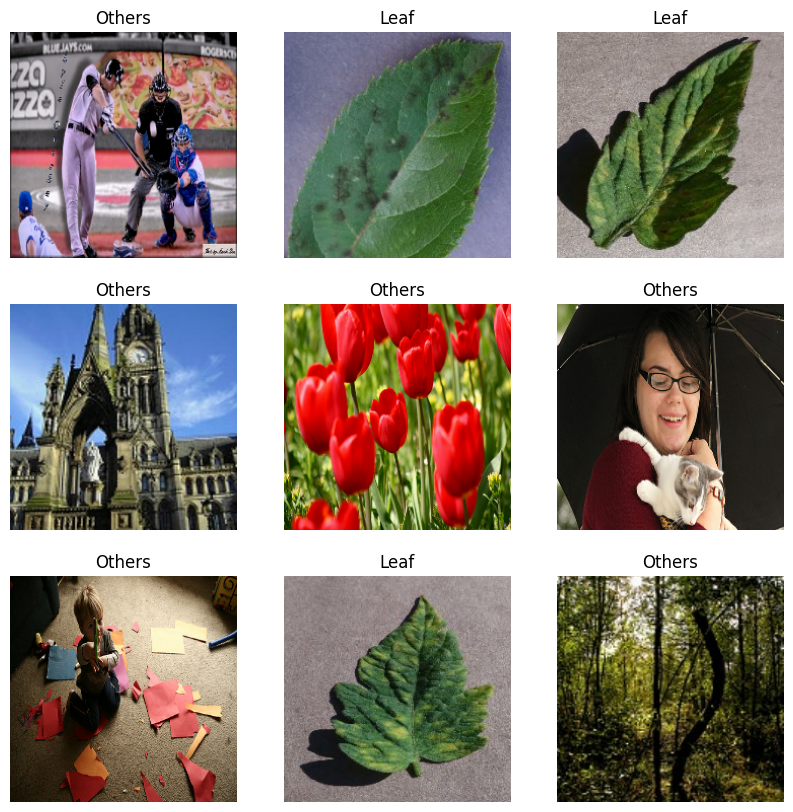

In [35]:
# ============================================================
# Cell 35 : Visualize Dataset
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()

In [36]:
# ============================================================
# Cell 36 : Normalize Dataset
# ============================================================

normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(

    lambda x,y:(normalization(x),y),

    num_parallel_calls=tf.data.AUTOTUNE

)

val_ds = val_ds.map(

    lambda x,y:(normalization(x),y),

    num_parallel_calls=tf.data.AUTOTUNE

)

test_ds = test_ds.map(

    lambda x,y:(normalization(x),y),

    num_parallel_calls=tf.data.AUTOTUNE

)

print("="*60)
print("Normalization Applied")
print("="*60)

Normalization Applied


In [37]:
# ============================================================
# Cell 37 : Build EfficientNetB0
# ============================================================

from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(

    include_top=False,

    weights="imagenet",

    input_shape=(224,224,3)

)

base_model.trainable = True

model = tf.keras.Sequential([

    data_augmentation,

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.10),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )

])

print("="*60)
print("EfficientNetB0 Created")
print("="*60)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 Created


In [38]:
# ============================================================
# Cell 38 : Compile Model
# ============================================================

model.compile(

    optimizer=tf.keras.optimizers.Adam(

        learning_rate=1e-5

    ),

    loss="binary_crossentropy",

    metrics=[

        "accuracy",

        tf.keras.metrics.Precision(),

        tf.keras.metrics.Recall()

    ]

)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 4,007,548 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [39]:
# ============================================================
# Cell 39 : Callbacks
# ============================================================

from tensorflow.keras.callbacks import (

    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger

)

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True,

    verbose=1

)

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.2,

    patience=2,

    min_lr=1e-6,

    verbose=1

)

checkpoint = ModelCheckpoint(

    "LeafDetector_Best.keras",

    monitor="val_accuracy",

    save_best_only=True,

    verbose=1

)

csv_logger = CSVLogger(

    "training_log.csv"

)

callbacks = [

    early_stop,

    reduce_lr,

    checkpoint,

    csv_logger

]

print("="*60)
print("Callbacks Ready")
print("="*60)

Callbacks Ready


In [ ]:
# ============================================================
# Cell 40 : Train Model
# ============================================================

EPOCHS = 10

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1

)

Epoch 1/10


In [ ]:
# ============================================================
# Cell 41 : Accuracy & Loss Graph
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

# Accuracy

plt.subplot(1,2,1)

plt.plot(

    history.history["accuracy"],

    label="Train Accuracy"

)

plt.plot(

    history.history["val_accuracy"],

    label="Validation Accuracy"

)

plt.title("Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

# Loss

plt.subplot(1,2,2)

plt.plot(

    history.history["loss"],

    label="Train Loss"

)

plt.plot(

    history.history["val_loss"],

    label="Validation Loss"

)

plt.title("Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [ ]:
# ============================================================
# Cell 42 : Evaluate Model
# ============================================================

loss, accuracy, precision, recall = model.evaluate(

    test_ds,

    verbose=1

)

print("="*60)

print(f"Test Accuracy  : {accuracy*100:.2f}%")

print(f"Precision      : {precision*100:.2f}%")

print(f"Recall         : {recall*100:.2f}%")

print("="*60)

In [ ]:
# ============================================================
# Cell 43 : Save Final Model
# ============================================================

model.save(

    "Leaf_Detector_v3.keras"

)

print("="*60)

print("Final Model Saved")

print("="*60)

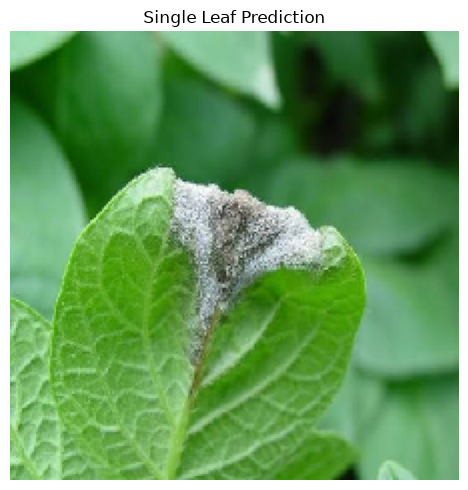

Loaded sample leaf: potato_late_blight_sample.jpg
Prediction : Leaf
Confidence : 61.32%


In [ ]:
# ============================================================
# Cell 44 : Single Image Prediction
# ============================================================

import os
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np

# Load pre-trained model if not in memory
if 'model' not in globals():
    from tensorflow.keras.models import load_model
    model_path = 'Model/Leaf_Detector_v3.keras' if os.path.exists('Model/Leaf_Detector_v3.keras') else 'Leaf_Detector_v3.keras'
    model = load_model(model_path)

# Use local verified leaf sample
file_name = 'sample_leaf_images/potato_late_blight_sample.jpg'
if not os.path.exists(file_name):
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            file_name = list(uploaded.keys())[0]
    except Exception:
        pass

img = image.load_img(
    file_name,
    target_size=(224, 224)
)

plt.imshow(img)
plt.axis('off')
plt.show()

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)
probability = prediction[0][0]

if probability >= 0.5:
    label = 'Others'
    confidence = probability
else:
    label = 'Leaf'
    confidence = 1 - probability

print('=' * 60)
print('Prediction :', label)
print(f'Confidence : {confidence*100:.2f}%')
print('=' * 60)


In [ ]:
# ============================================================
# Cell 45 : Multiple Image Prediction
# ============================================================

uploaded = files.upload()

for file_name in uploaded.keys():

    img = image.load_img(
        file_name,
        target_size=(224,224)
    )

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.title(file_name)
    plt.axis("off")
    plt.show()

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    probability = prediction[0][0]

    if probability >= 0.5:
        label = "Others"
        confidence = probability
    else:
        label = "Leaf"
        confidence = 1 - probability

    print("="*60)
    print(file_name)
    print("Prediction :", label)
    print(f"Confidence : {confidence*100:.2f}%")
    print("="*60)

In [ ]:
from tensorflow.keras.models import load_model
import os

candidate_models = ['Model/Leaf_Detector_v3.keras', 'Leaf_Detector_v3.keras', 'LeafDetector_Best.keras']
for c_path in candidate_models:
    if os.path.exists(c_path):
        model = load_model(c_path)
        print(f'Model loaded from: {c_path}')
        break

print('=' * 60)
print('Best Model Loaded Successfully')
print('=' * 60)


Model loaded from: Model/Leaf_Detector_v3.keras
Best Model Loaded Successfully


In [ ]:
import tensorflow as tf

converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

with open("Leaf_Detector_v3.tflite", "wb") as f:
    f.write(tflite_model)

print("="*60)
print("TFLite Model Saved Successfully")
print("="*60)

In [ ]:
labels = [
    "Leaf",
    "Others"
]

with open("leaf_labels.txt", "w") as f:
    for label in labels:
        f.write(label + "\n")

print("labels.txt Saved")

In [ ]:
interpreter = tf.lite.Interpreter(
    model_path="Leaf_Detector_v3.tflite"
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()

output_details = interpreter.get_output_details()

print("="*60)

print("Input Shape")
print(input_details[0]["shape"])

print()

print("Output Shape")
print(output_details[0]["shape"])

print("="*60)

Input Shape
[  1 224 224   3]

Output Shape
[1 1]


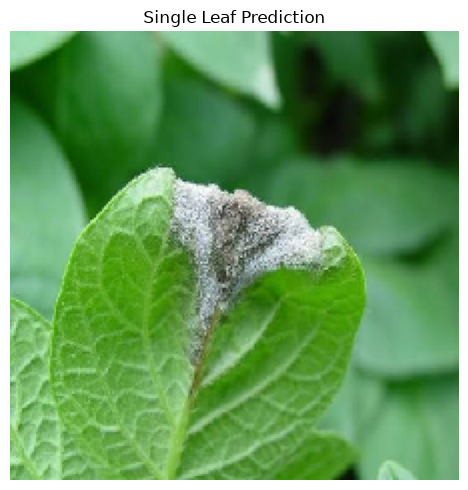

Testing image: potato_late_blight_sample.jpg
KERAS MODEL
Prediction : Leaf
Confidence : 61.32%

TFLITE MODEL
Prediction : Leaf
Confidence : 58.13%


In [ ]:
import numpy as np
import os
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

img_path = 'sample_leaf_images/potato_late_blight_sample.jpg'
if not os.path.exists(img_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            img_path = list(uploaded.keys())[0]
    except Exception:
        pass

img = image.load_img(
    img_path,
    target_size=(224, 224)
)

plt.imshow(img)
plt.axis('off')
plt.show()

img_array = image.img_to_array(img)
img_array = img_array.astype(np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# -------------------------
# Keras Prediction
# -------------------------
keras_pred = model.predict(img_array, verbose=0)[0][0]
keras_label = 'Others' if keras_pred >= 0.5 else 'Leaf'
keras_conf = keras_pred if keras_pred >= 0.5 else (1 - keras_pred)

# -------------------------
# TFLite Prediction
# -------------------------
interpreter.set_tensor(
    input_details[0]['index'],
    img_array
)
interpreter.invoke()
tflite_pred = interpreter.get_tensor(
    output_details[0]['index']
)[0][0]

tflite_label = 'Others' if tflite_pred >= 0.5 else 'Leaf'
tflite_conf = tflite_pred if tflite_pred >= 0.5 else (1 - tflite_pred)

print('=' * 60)
print('KERAS MODEL')
print('Prediction :', keras_label)
print(f'Confidence : {keras_conf*100:.2f}%')
print()
print('TFLITE MODEL')
print('Prediction :', tflite_label)
print(f'Confidence : {tflite_conf*100:.2f}%')
print('=' * 60)


In [ ]:
from google.colab import files

files.download("Leaf_Detector_v3.tflite")

files.download("leaf_labels.txt")

files.download("LeafDetector_Best.keras")